In [1]:
# Cell 1: Setup
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Sẵn sàng hoạt động trên thiết bị: {device}")

Sẵn sàng hoạt động trên thiết bị: cpu


In [2]:
# Cell 2: Core Components Definition

# --- Môi trường Kịch bản 3 Giai đoạn ---
class UltimateDynamicMosEnv(gym.Env):
    def __init__(self):
        super(UltimateDynamicMosEnv, self).__init__()
        self.max_steps = 200
        self.paths = {0:[1, 8], 1:[2, 6, 9], 2:[0, 3, 8], 3:[2, 5, 8]}
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Box(low=0, high=500, shape=(20,), dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        return np.ones(20, dtype=np.float32) * 20.0, {}

    def step(self, action):
        self.current_step += 1
        self.state = np.random.uniform(15.0, 25.0, 20).astype(np.float32)
        for i in range(10): self.state[i*2+1] = 0.0

        if 20 <= self.current_step < 70: self.state[3*2] = 350.0; self.state[3*2+1] = 20.0
        elif 70 <= self.current_step < 130: self.state[6*2] = 350.0; self.state[6*2+1] = 20.0
        elif self.current_step >= 130: self.state[3*2] = 350.0; self.state[3*2+1] = 20.0; self.state[6*2] = 350.0; self.state[6*2+1] = 20.0

        links = self.paths[action]
        d = sum([self.state[i*2] for i in links])
        l = (1 - np.prod([(1 - self.state[i*2+1]/100) for i in links])) * 100
        mos = float(np.clip(5.0 - (max(0, d-50)*0.005) - (l*0.2), 1.0, 5.0))
        return self.state, mos, False, self.current_step >= self.max_steps, {"mos": mos}

# --- Bộ não AI (Neural Network) ---
class DQNNetwork(nn.Module):
    def __init__(self, state_size=20, action_size=4):
        super(DQNNetwork, self).__init__()
        self.net = nn.Sequential(nn.Linear(state_size, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, action_size))
    def forward(self, state): return self.net(state)

# --- Replay Buffer ---
class ReplayBuffer:
    def __init__(self, capacity): self.buffer = deque(maxlen=capacity)
    def push(self, *args): self.buffer.append(args)
    def sample(self, batch_size):
        batch = random.sample(self.buffer, min(batch_size, len(self.buffer)))
        states, actions, rewards, next_states, dones = zip(*batch)
        return torch.tensor(np.array(states), device=device), torch.tensor(actions, device=device), \
               torch.tensor(rewards, device=device), torch.tensor(np.array(next_states), device=device), \
               torch.tensor(dones, device=device)
    def __len__(self): return len(self.buffer)

# --- Agent Tổng hợp (DQN) ---
class DQNAgent:
    def __init__(self, state_size=20, action_size=4, lr=1e-3, gamma=0.99, epsilon=1.0, epsilon_decay=0.995, epsilon_min=0.05):
        self.action_size = action_size; self.gamma = gamma; self.epsilon = epsilon
        self.epsilon_decay = epsilon_decay; self.epsilon_min = epsilon_min
        self.q_network = DQNNetwork(state_size, action_size).to(device)
        self.target_network = DQNNetwork(state_size, action_size).to(device)
        self.target_network.load_state_dict(self.q_network.state_dict())
        self.optimizer = optim.Adam(self.q_network.parameters(), lr=lr)
        self.replay_buffer = ReplayBuffer(10000)

    def select_action(self, state, training=True):
        if training and random.random() < self.epsilon: return random.randint(0, self.action_size - 1)
        with torch.no_grad(): return self.q_network(torch.tensor(state, device=device)).argmax().item()

    def train_step(self, batch_size=64):
        if len(self.replay_buffer) < batch_size: return None
        states, actions, rewards, next_states, dones = self.replay_buffer.sample(batch_size)
        q_vals = self.q_network(states).gather(1, actions.unsqueeze(-1)).squeeze(-1)
        with torch.no_grad():
            next_q_vals = self.target_network(next_states).max(1)[0]
            target_q_vals = rewards + (self.gamma * next_q_vals * (1 - dones.float()))
        loss = nn.MSELoss()(q_vals, target_q_vals)
        self.optimizer.zero_grad(); loss.backward(); self.optimizer.step()
        return loss.item()

    def update_target_network(self): self.target_network.load_state_dict(self.q_network.state_dict())
    def decay_epsilon(self): self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

print("Đã định nghĩa xong Môi trường, Não bộ AI, và Agent!")

Đã định nghĩa xong Môi trường, Não bộ AI, và Agent!



Bắt đầu huấn luyện qua 1500 episodes...
----------------------------------------------------------------------
Episode  100/1500 | Avg Reward:  795.84 | Epsilon: 0.606
Episode  200/1500 | Avg Reward:  874.97 | Epsilon: 0.367
Episode  300/1500 | Avg Reward:  920.80 | Epsilon: 0.222
Episode  400/1500 | Avg Reward:  949.73 | Epsilon: 0.135
Episode  500/1500 | Avg Reward:  967.09 | Epsilon: 0.082
Episode  600/1500 | Avg Reward:  977.06 | Epsilon: 0.050
Episode  700/1500 | Avg Reward:  982.10 | Epsilon: 0.050
Episode  800/1500 | Avg Reward:  979.95 | Epsilon: 0.050
Episode  900/1500 | Avg Reward:  979.30 | Epsilon: 0.050
Episode 1000/1500 | Avg Reward:  981.05 | Epsilon: 0.050
Episode 1100/1500 | Avg Reward:  981.90 | Epsilon: 0.050
Episode 1200/1500 | Avg Reward:  981.44 | Epsilon: 0.050
Episode 1300/1500 | Avg Reward:  980.81 | Epsilon: 0.050
Episode 1400/1500 | Avg Reward:  980.02 | Epsilon: 0.050
Episode 1500/1500 | Avg Reward:  981.07 | Epsilon: 0.050
---------------------------------

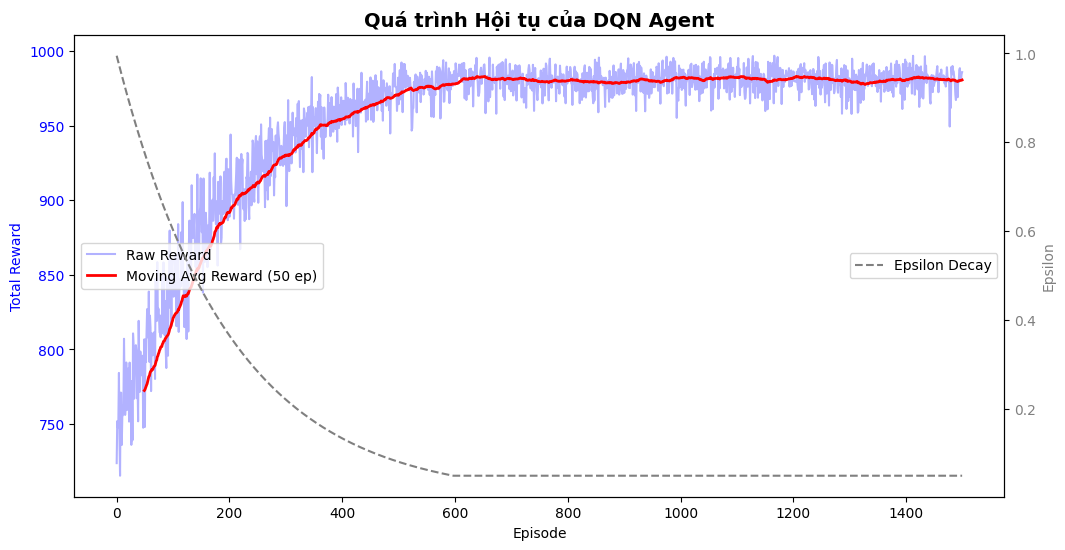

In [3]:
# Cell 3: Training & Convergence Visualization
env_train = UltimateDynamicMosEnv()
agent = DQNAgent(state_size=20, action_size=4)
num_episodes = 1500
batch_size = 64
episode_rewards, losses, epsilon_history = [], [], []

print(f"\nBắt đầu huấn luyện qua {num_episodes} episodes...")
print("-" * 70)

for episode in range(num_episodes):
    state, _ = env_train.reset()
    episode_reward, episode_loss, done = 0, 0, False
    
    while not done:
        action = agent.select_action(state, training=True)
        next_state, reward, term, trunc, _ = env_train.step(action)
        done = term or trunc
        agent.replay_buffer.push(state, action, reward, next_state, done)
        loss_val = agent.train_step(batch_size)
        if loss_val: episode_loss += loss_val
        episode_reward += reward
        state = next_state
        
    agent.decay_epsilon()
    if episode % 100 == 0: agent.update_target_network() # Cập nhật Target Network mỗi 100 episodes
    
    episode_rewards.append(episode_reward)
    losses.append(episode_loss)
    epsilon_history.append(agent.epsilon)
    
    if (episode + 1) % 100 == 0:
        avg_reward = np.mean(episode_rewards[-100:])
        print(f"Episode {episode+1:4d}/{num_episodes} | Avg Reward: {avg_reward:7.2f} | Epsilon: {agent.epsilon:.3f}")

print("-" * 70)
print("Huấn luyện hoàn tất!")

# Trực quan hóa quá trình học
fig, ax1 = plt.subplots(figsize=(12, 6))
# Trục trái: Reward
ax1.plot(episode_rewards, alpha=0.3, color='blue', label='Raw Reward')
ma_rewards = np.convolve(episode_rewards, np.ones(50)/50, mode='valid')
ax1.plot(range(49, len(episode_rewards)), ma_rewards, color='red', linewidth=2, label='Moving Avg Reward (50 ep)')
ax1.set_xlabel('Episode'); ax1.set_ylabel('Total Reward', color='blue'); ax1.tick_params(axis='y', labelcolor='blue')
# Trục phải: Epsilon
ax2 = ax1.twinx()
ax2.plot(epsilon_history, color='gray', linestyle='--', label='Epsilon Decay')
ax2.set_ylabel('Epsilon', color='gray'); ax2.tick_params(axis='y', labelcolor='gray')
plt.title('Quá trình Hội tụ của DQN Agent', fontsize=14, fontweight='bold')
ax1.legend(loc='center left'); ax2.legend(loc='center right'); plt.show()


Bắt đầu chạy Đánh giá cuối cùng...
Hoàn tất! Đang vẽ biểu đồ kết quả...


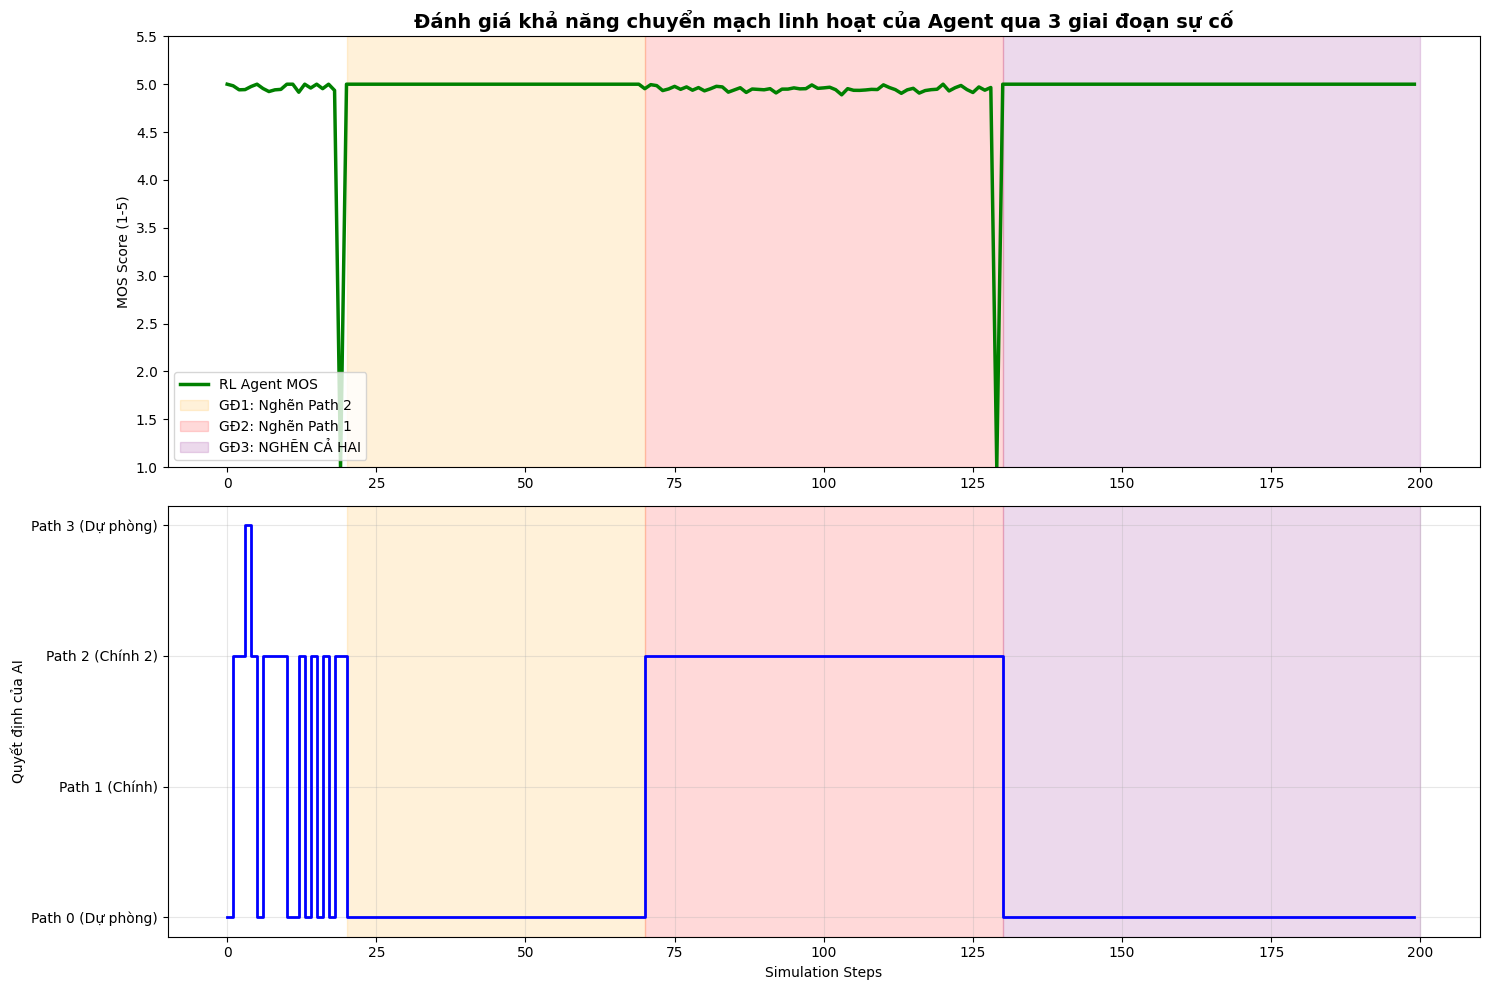

In [4]:
# Cell 4: Advanced Evaluation & Visualization
def evaluate_ultimate(trained_agent):
    env_eval = UltimateDynamicMosEnv()
    obs, _ = env_eval.reset()
    history = {"mos": [], "actions": []}
    for _ in range(200):
        action = trained_agent.select_action(obs, training=False)
        obs, _, _, _, info = env_eval.step(action)
        history["mos"].append(info["mos"])
        history["actions"].append(action)
    return history

print("\nBắt đầu chạy Đánh giá cuối cùng...")
final_results = evaluate_ultimate(agent)
print("Hoàn tất! Đang vẽ biểu đồ kết quả...")

# Vẽ biểu đồ 3 giai đoạn
plt.figure(figsize=(15, 10))

# Biểu đồ MOS
plt.subplot(2, 1, 1)
plt.plot(final_results["mos"], color='green', label='RL Agent MOS', linewidth=2.5)
plt.axvspan(20, 70, color='orange', alpha=0.15, label='GĐ1: Nghẽn Path 2')
plt.axvspan(70, 130, color='red', alpha=0.15, label='GĐ2: Nghẽn Path 1')
plt.axvspan(130, 200, color='purple', alpha=0.15, label='GĐ3: NGHẼN CẢ HAI')
plt.ylabel("MOS Score (1-5)"); plt.ylim(1, 5.5); plt.legend(loc='lower left')
plt.title("Đánh giá khả năng chuyển mạch linh hoạt của Agent qua 3 giai đoạn sự cố", fontsize=14, fontweight='bold')

# Biểu đồ Actions
plt.subplot(2, 1, 2)
plt.step(range(200), final_results["actions"], where='post', color='blue', linewidth=2)
plt.axvspan(20, 70, color='orange', alpha=0.15); plt.axvspan(70, 130, color='red', alpha=0.15)
plt.axvspan(130, 200, color='purple', alpha=0.15)
plt.yticks([0, 1, 2, 3], ['Path 0 (Dự phòng)', 'Path 1 (Chính)', 'Path 2 (Chính 2)', 'Path 3 (Dự phòng)'])
plt.ylabel("Quyết định của AI"); plt.xlabel("Simulation Steps"); plt.grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

Xuất file mô hình .pth

In [5]:
import torch
# Lưu trọng số của mạng Nơ-ron
torch.save(agent.q_network.state_dict(), "dqn_routing_ultimate.pth")
print("Đã xuất file dqn_routing_ultimate.pth thành công!")

Đã xuất file dqn_routing_ultimate.pth thành công!
